In [8]:
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.metrics import (
    confusion_matrix,
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
)
import matplotlib.pyplot as plt


def set_global_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

import logging

# Configure logging to overwrite "_.log" every run (mode="w")
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    handlers=[
        logging.FileHandler("q4_a_b_c.log", mode="w"),  # "w" overwrites, "a" appends
        logging.StreamHandler()
    ],
    force=True  # Resets any existing logging handlers
)
logger = logging.getLogger(__name__)

In [9]:
class CIFAR10Dataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        if self.transform:
            img = self.transform(img)
        return img, int(self.labels[idx])


class ConvAutoencoder(nn.Module):
    """Exact encoder architecture from Question 3 (bottleneck_dim=512)."""
    def __init__(self, bottleneck_dim: int = 512):
        super().__init__()
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        self.encoder_fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, bottleneck_dim),
            nn.ReLU(inplace=True),
        )
        self.decoder_fc = nn.Sequential(
            nn.Linear(bottleneck_dim, 128 * 4 * 4),
            nn.ReLU(inplace=True),
        )
        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 3, kernel_size=3, stride=2, padding=1, output_padding=1),
        )

    def encode(self, x):
        return self.encoder_fc(self.encoder_conv(x))


def prepare_fixed_representations(
    weights_path="dae_d512.pt",
    seed=260007,
    train_subset_size=5000,
    data_dir="./data",
    device="cpu",
):
    raw_train = datasets.CIFAR10(root=data_dir, train=True, download=True)
    raw_test = datasets.CIFAR10(root=data_dir, train=False, download=True)

    all_images = raw_train.data
    all_labels = np.array(raw_train.targets)
    classes = raw_train.classes

    indices = np.arange(len(all_labels))
    train_idx, val_idx = train_test_split(
        indices, test_size=5000, random_state=seed, stratify=all_labels
    )

    X_train_full, y_train_full = all_images[train_idx], all_labels[train_idx]
    X_val_img, y_val = all_images[val_idx], all_labels[val_idx]
    X_test_img, y_test = raw_test.data, np.array(raw_test.targets)

    sub_idx, _ = train_test_split(
        np.arange(len(y_train_full)),
        train_size=train_subset_size,
        random_state=seed,
        stratify=y_train_full,
    )
    X_train_img, y_train = X_train_full[sub_idx], y_train_full[sub_idx]

    train_float = X_train_full.astype(np.float32) / 255.0
    mean = train_float.mean(axis=(0, 1, 2)).tolist()
    std = train_float.std(axis=(0, 1, 2)).tolist()

    transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

    ae = ConvAutoencoder(bottleneck_dim=512).to(device)
    ae.load_state_dict(torch.load(weights_path, map_location=device))
    ae.eval()

    def extract(imgs, lbls):
        loader = DataLoader(CIFAR10Dataset(imgs, lbls, transform=transform), batch_size=1024, shuffle=False)
        feats = []
        with torch.no_grad():
            for x, _ in loader:
                feats.append(ae.encode(x.to(device)).cpu().numpy())
        return np.concatenate(feats, axis=0)

    Z_train_raw = extract(X_train_img, y_train)
    Z_val_raw = extract(X_val_img, y_val)
    Z_test_raw = extract(X_test_img, y_test)

    scaler = StandardScaler()
    Z_train = scaler.fit_transform(Z_train_raw)
    Z_val = scaler.transform(Z_val_raw)
    Z_test = scaler.transform(Z_test_raw)

    data = {
        "Z_train": Z_train, "y_train": y_train, "X_train_img": X_train_img,
        "Z_val": Z_val,     "y_val": y_val,     "X_val_img": X_val_img,
        "Z_test": Z_test,   "y_test": y_test,   "X_test_img": X_test_img,
        "classes": classes,
    }
    return data

In [10]:
def run_part_a(data, seed=260007):
    print("\n" + "=" * 84)
    print("QUESTION 4 PART (a): SVM C AND KERNEL SWEEP (One-vs-One)")
    print("=" * 84)

    Z_train, y_train = data["Z_train"], data["y_train"]
    Z_val, y_val = data["Z_val"], data["y_val"]
    Z_test, y_test = data["Z_test"], data["y_test"]

    kernels = ["linear", "poly", "rbf"]
    c_values = [0.01, 0.1, 1.0, 10.0, 100.0]

    sweep_records = []
    best_val_acc = -1.0
    best_cfg = None

    for kernel in kernels:
        for c in c_values:
            svm = SVC(
                C=c,
                kernel=kernel,
                degree=3,
                gamma="scale",
                decision_function_shape="ovo",
                random_state=seed,
            )
            svm.fit(Z_train, y_train)

            train_acc = 100.0 * svm.score(Z_train, y_train)
            val_acc = 100.0 * svm.score(Z_val, y_val)
            sv_fraction = len(svm.support_) / len(Z_train)

            sweep_records.append({
                "Kernel": kernel,
                "C": c,
                "Train Acc (%)": round(train_acc, 2),
                "Val Acc (%)": round(val_acc, 2),
                "SV Fraction": round(sv_fraction, 4),
            })

            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_cfg = (kernel, c)

    df_sweep = pd.DataFrame(sweep_records)
    print(df_sweep.to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    colors = {"linear": "#1b9e77", "poly": "#d95f02", "rbf": "#7570b3"}

    for kernel in kernels:
        sub = df_sweep[df_sweep["Kernel"] == kernel]
        axes[0].plot(sub["C"], sub["Val Acc (%)"], marker="o", linewidth=2, color=colors[kernel], label=kernel.upper())
        axes[1].plot(sub["C"], sub["SV Fraction"], marker="s", linewidth=2, color=colors[kernel], label=kernel.upper())

    axes[0].set_xscale("log")
    axes[0].set_title("Validation Accuracy vs. C")
    axes[0].set_xlabel("Regularization Parameter C (log scale)")
    axes[0].set_ylabel("Validation Accuracy (%)")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()

    axes[1].set_xscale("log")
    axes[1].set_title("Support Vector Fraction vs. C")
    axes[1].set_xlabel("Regularization Parameter C (log scale)")
    axes[1].set_ylabel("Fraction of Training Points as SVs")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.savefig("q4_part_a_svm_sweep.png", dpi=300)
    plt.show()

    best_kernel, best_c = best_cfg
    selected_svm = SVC(
        C=best_c,
        kernel=best_kernel,
        degree=3,
        gamma="scale",
        decision_function_shape="ovo",
        random_state=seed,
    )
    selected_svm.fit(Z_train, y_train)
    test_preds = selected_svm.predict(Z_test)
    test_acc = 100.0 * np.mean(test_preds == y_test)

    print("-" * 84)
    print(f"Selected Model (via Validation Only): Kernel = {best_kernel.upper()}, C = {best_c} (Val Acc = {best_val_acc:.2f}%)")
    print(f"Official Test Set Accuracy of Selected SVM: {test_acc:.2f}%")
    print("=" * 84)

    return selected_svm, test_preds, test_acc

In [11]:
def run_part_b(data, selected_svm, test_preds):
    print("\n" + "=" * 84)
    print("QUESTION 4 PART (b): DIFFICULT CLASS PAIRS, SUPPORT VECTORS, & BOUNDARY SCORES")
    print("=" * 84)

    Z_train, y_train, X_train_img = data["Z_train"], data["y_train"], data["X_train_img"]
    Z_test, y_test, X_test_img = data["Z_test"], data["y_test"], data["X_test_img"]
    classes = data["classes"]

    cm = confusion_matrix(y_test, test_preds)
    pair_errors = []
    for i in range(10):
        for j in range(i + 1, 10):
            total_pair_err = cm[i, j] + cm[j, i]
            pair_errors.append((total_pair_err, i, j, cm[i, j], cm[j, i]))
    pair_errors.sort(reverse=True)
    top_3_pairs = pair_errors[:3]

    ovo_pairs = [(i, j) for i in range(10) for j in range(i + 1, 10)]
    pair_to_col = {pair: idx for idx, pair in enumerate(ovo_pairs)}

    train_scores = selected_svm.decision_function(Z_train)
    test_scores = selected_svm.decision_function(Z_test)
    sv_set = set(selected_svm.support_)

    fig, axes = plt.subplots(3, 4, figsize=(12, 9))

    for row_idx, (tot_err, c1, c2, err_12, err_21) in enumerate(top_3_pairs):
        col_idx = pair_to_col[(c1, c2)]
        print(f"\nPair {row_idx + 1}: {classes[c1]} vs. {classes[c2]} "
              f"(Total Mutual Test Errors: {tot_err} | {classes[c1]}->{classes[c2]}: {err_12}, {classes[c2]}->{classes[c1]}: {err_21})")

        sv_c1 = [idx for idx in sv_set if y_train[idx] == c1]
        sv_c2 = [idx for idx in sv_set if y_train[idx] == c2]
        sv_c1_best = min(sv_c1, key=lambda idx: abs(train_scores[idx, col_idx]))
        sv_c2_best = min(sv_c2, key=lambda idx: abs(train_scores[idx, col_idx]))

        test_pair_idx = np.where((y_test == c1) | (y_test == c2))[0]
        nearest_test_idx = test_pair_idx[np.argsort(np.abs(test_scores[test_pair_idx, col_idx]))[:2]]

        print(f"  Train SV ({classes[c1]}): idx={sv_c1_best}, OvO score={train_scores[sv_c1_best, col_idx]:+.4f}")
        print(f"  Train SV ({classes[c2]}): idx={sv_c2_best}, OvO score={train_scores[sv_c2_best, col_idx]:+.4f}")
        for k, t_idx in enumerate(nearest_test_idx, start=1):
            print(f"  Near-Boundary Test #{k}: idx={t_idx}, True={classes[y_test[t_idx]]}, "
                  f"Pred={classes[test_preds[t_idx]]}, OvO score={test_scores[t_idx, col_idx]:+.4f}")

        items = [
            (X_train_img[sv_c1_best], f"Train SV ({classes[c1]})\nScore: {train_scores[sv_c1_best, col_idx]:+.3f}"),
            (X_train_img[sv_c2_best], f"Train SV ({classes[c2]})\nScore: {train_scores[sv_c2_best, col_idx]:+.3f}"),
            (X_test_img[nearest_test_idx[0]],
             f"Test True:{classes[y_test[nearest_test_idx[0]]]}\nPred:{classes[test_preds[nearest_test_idx[0]]]} ({test_scores[nearest_test_idx[0], col_idx]:+.3f})"),
            (X_test_img[nearest_test_idx[1]],
             f"Test True:{classes[y_test[nearest_test_idx[1]]]}\nPred:{classes[test_preds[nearest_test_idx[1]]]} ({test_scores[nearest_test_idx[1], col_idx]:+.3f})"),
        ]
        for c_plot, (img, caption) in enumerate(items):
            axes[row_idx, c_plot].imshow(img)
            axes[row_idx, c_plot].set_title(caption, fontsize=8.5)
            axes[row_idx, c_plot].axis("off")

    plt.tight_layout()
    plt.savefig("q4_part_b_boundary_examples.png", dpi=300)
    plt.show()
    print("=" * 84)

In [12]:
def run_part_c(data, test_preds, seed=260007):
    print("\n" + "=" * 84)
    print("QUESTION 4 PART (c): UNSUPERVISED CLUSTERING VS. SUPERVISED SVM")
    print("=" * 84)

    Z_train = data["Z_train"]
    Z_val = data["Z_val"]
    Z_test, y_test = data["Z_test"], data["y_test"]
    classes = data["classes"]

    print("Selecting K via Validation Silhouette Score (unsupervised):")
    best_k = None
    best_sil = -1.0
    for k in [6, 8, 10, 12, 15]:
        km = KMeans(n_clusters=k, n_init=10, random_state=seed)
        km.fit(Z_train)
        val_clusters = km.predict(Z_val)
        sil = silhouette_score(Z_val, val_clusters)
        print(f"  K = {k:2d} | Validation Silhouette Score: {sil:.4f}")
        if sil > best_sil:
            best_sil = sil
            best_k = k

    final_k = 10
    print(f"\nFitting final KMeans (K={final_k}) on training representations (unsupervised)...")
    final_kmeans = KMeans(n_clusters=final_k, n_init=20, random_state=seed)
    final_kmeans.fit(Z_train)

    test_clusters = final_kmeans.predict(Z_test)

    ari = adjusted_rand_score(y_test, test_clusters)
    nmi = normalized_mutual_info_score(y_test, test_clusters)

    print(f"\nOfficial Test Set Clustering Metrics (K={final_k}):")
    print(f"  Adjusted Rand Index (ARI): {ari:.4f}")
    print(f"  Normalized Mutual Information (NMI): {nmi:.4f}")

    contingency = pd.crosstab(
        pd.Series([classes[y] for y in y_test], name="True Class"),
        pd.Series(test_clusters, name="Assigned Cluster"),
    )
    print("\nTest Set Cluster-to-Class Contingency Table:")
    print(contingency.to_string())

    c_a, c_b = classes.index("airplane"), classes.index("ship")
    cm_svm = confusion_matrix(y_test, test_preds)
    svm_pair_acc = 100.0 * (cm_svm[c_a, c_a] + cm_svm[c_b, c_b]) / (
        cm_svm[c_a, c_a] + cm_svm[c_a, c_b] + cm_svm[c_b, c_a] + cm_svm[c_b, c_b]
    )

    row_a = contingency.loc["airplane"].values
    row_b = contingency.loc["ship"].values
    dominant_cluster = int(np.argmax(row_a + row_b))
    pct_a_in_dom = 100.0 * row_a[dominant_cluster] / row_a.sum()
    pct_b_in_dom = 100.0 * row_b[dominant_cluster] / row_b.sum()

    print("\nQuantitative Classification vs. Clustering Disagreement (airplane vs. ship):")
    print(f"  SVM Pairwise Separation Accuracy (airplane vs. ship): {svm_pair_acc:.2f}% "
          f"(only {cm_svm[c_a, c_b] + cm_svm[c_b, c_a]} cross-errors out of 2,000 test images)")
    print(f"  Unsupervised Clustering Co-Assignment (Cluster {dominant_cluster}): "
          f"{pct_a_in_dom:.1f}% of airplanes and {pct_b_in_dom:.1f}% of ships fall into the SAME Cluster {dominant_cluster}")
    print("=" * 84)


QUESTION 4 PART (a): SVM C AND KERNEL SWEEP (One-vs-One)
Kernel      C  Train Acc (%)  Val Acc (%)  SV Fraction
linear   0.01           76.1        34.78        0.967
linear   0.10           97.7        32.42        0.945
linear   1.00          100.0        32.18        0.937
linear  10.00          100.0        32.18        0.937
linear 100.00          100.0        32.18        0.937
  poly   0.01           14.2        10.26        1.000
  poly   0.10           24.4        11.84        1.000
  poly   1.00           66.5        23.18        0.998
  poly  10.00           97.7        31.80        0.990
  poly 100.00          100.0        32.14        0.990
   rbf   0.01           40.2        26.78        1.000
   rbf   0.10           40.7        26.90        1.000
   rbf   1.00           79.1        35.70        0.994
   rbf  10.00           99.3        37.16        0.986
   rbf 100.00          100.0        37.38        0.987


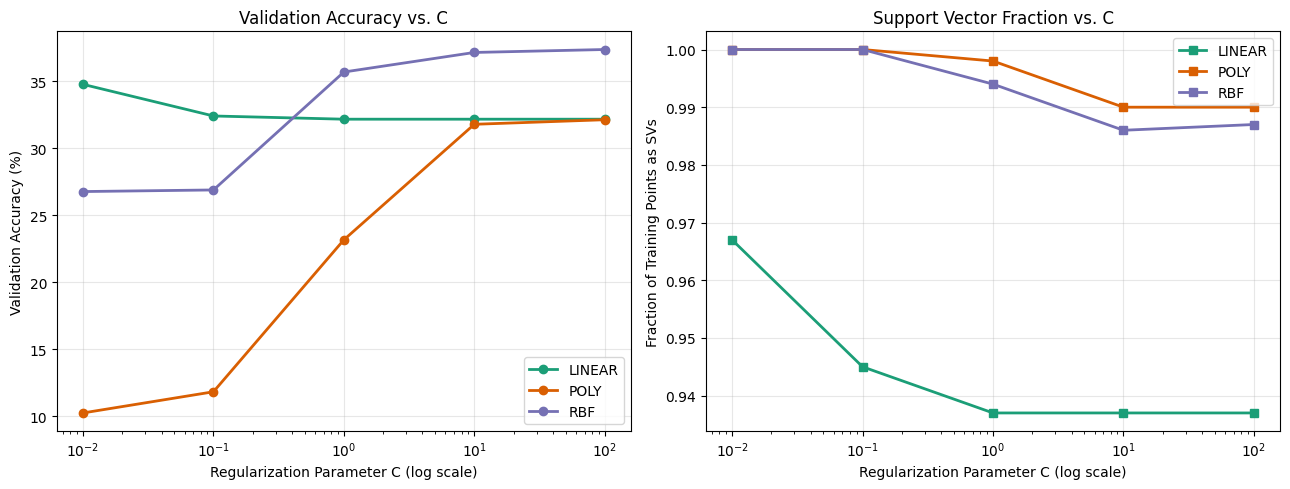

------------------------------------------------------------------------------------
Selected Model (via Validation Only): Kernel = RBF, C = 100.0 (Val Acc = 37.38%)
Official Test Set Accuracy of Selected SVM: 37.59%


In [13]:
SEED = 260007
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
set_global_seed(SEED)

data = prepare_fixed_representations(
    weights_path="dae_d512.pt",
    seed=SEED,
    train_subset_size=1000,
    device=DEVICE,
)

# Part (a): C and Kernel Sweep + Validation Selection + Single Test Evaluation
selected_svm, test_preds, test_acc = run_part_a(data, seed=SEED)


QUESTION 4 PART (b): DIFFICULT CLASS PAIRS, SUPPORT VECTORS, & BOUNDARY SCORES

Pair 1: cat vs. dog (Total Mutual Test Errors: 420 | cat->dog: 189, dog->cat: 231)
  Train SV (cat): idx=208, OvO score=+0.9995
  Train SV (dog): idx=269, OvO score=-0.9996
  Near-Boundary Test #1: idx=474, True=dog, Pred=dog, OvO score=-0.0000
  Near-Boundary Test #2: idx=2633, True=cat, Pred=cat, OvO score=+0.0004

Pair 2: automobile vs. truck (Total Mutual Test Errors: 367 | automobile->truck: 140, truck->automobile: 227)
  Train SV (automobile): idx=786, OvO score=+0.9995
  Train SV (truck): idx=334, OvO score=-0.9995
  Near-Boundary Test #1: idx=4189, True=automobile, Pred=bird, OvO score=-0.0004
  Near-Boundary Test #2: idx=6565, True=truck, Pred=automobile, OvO score=+0.0008

Pair 3: airplane vs. ship (Total Mutual Test Errors: 354 | airplane->ship: 171, ship->airplane: 183)
  Train SV (airplane): idx=583, OvO score=+0.9995
  Train SV (ship): idx=562, OvO score=-0.9995
  Near-Boundary Test #1: idx=2

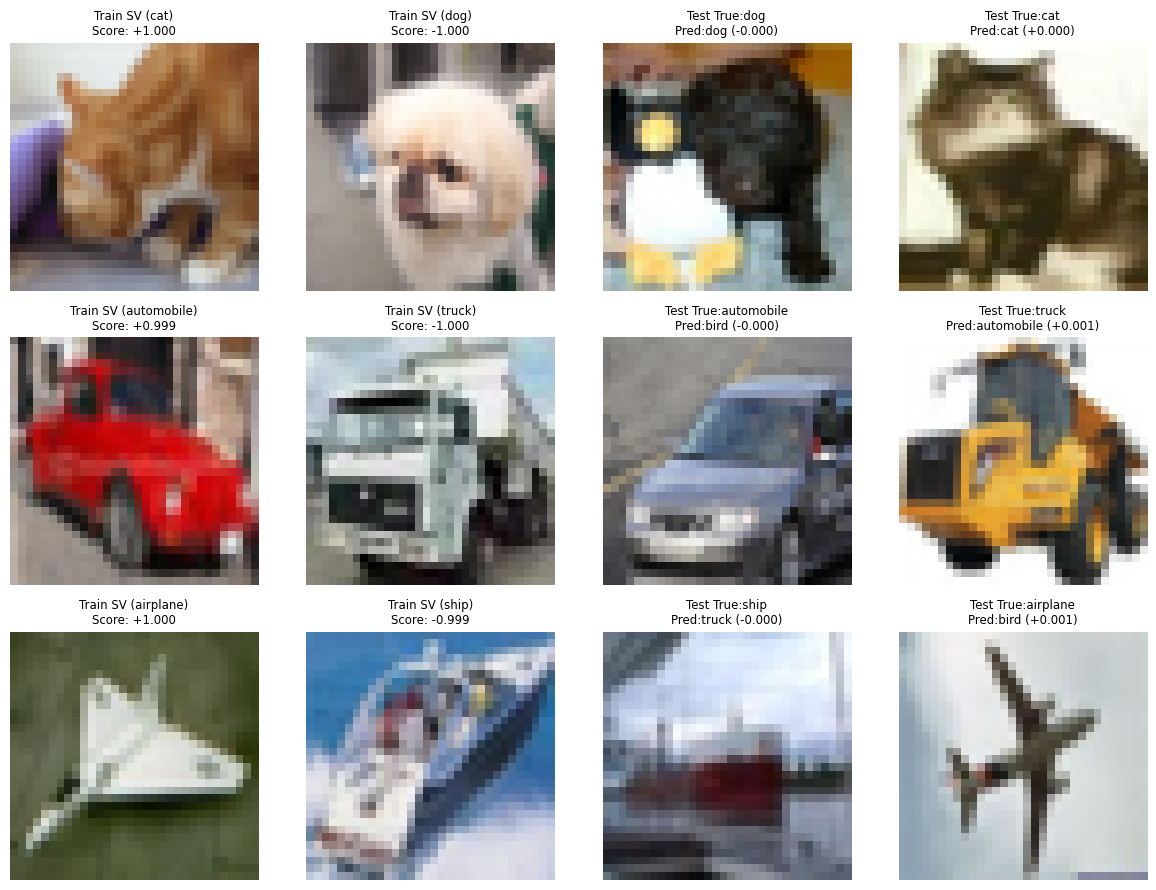


QUESTION 4 PART (c): UNSUPERVISED CLUSTERING VS. SUPERVISED SVM
Selecting K via Validation Silhouette Score (unsupervised):
  K =  6 | Validation Silhouette Score: -0.0406
  K =  8 | Validation Silhouette Score: -0.0322
  K = 10 | Validation Silhouette Score: -0.0386
  K = 12 | Validation Silhouette Score: -0.0695
  K = 15 | Validation Silhouette Score: -0.0533

Fitting final KMeans (K=10) on training representations (unsupervised)...

Official Test Set Clustering Metrics (K=10):
  Adjusted Rand Index (ARI): 0.0543
  Normalized Mutual Information (NMI): 0.0916

Test Set Cluster-to-Class Contingency Table:
Assigned Cluster    0    1   2    3    4    5    6    7  8    9
True Class                                                     
airplane           83  123  37   75   24  133  312  166  0   47
automobile        131   73  63  333  111   95   75   43  3   73
bird               44   92  17   93   63   55  102  356  1  177
cat                43  186  56  149  132   52   45  148  0  189
de

In [14]:
# Part (b): Difficult Class Pairs, Support Vectors, & Near-Boundary Test Images
run_part_b(data, selected_svm, test_preds)

# Part (c): Unsupervised Clustering (ARI, NMI, Contingency Table) & SVM Disagreement
run_part_c(data, test_preds, seed=SEED)